# Data Structures & Algorithms: Arrays, Strings and Problem-Solving Techniques

> **Who is this for:** learners who know basic Python lists and loops and want to solve array/string problems efficiently, whether for a university DSA course, a coding interview, or writing fast data-processing code.
>
> **What you will learn:**
> - Static vs. dynamic arrays, how arrays sit in memory, Python lists vs. NumPy arrays, 2-D matrix tricks (transpose, rotate, spiral)
> - Strings: immutability, building strings efficiently, palindromes and anagrams
> - The six patterns behind most array interview questions, each with a brute force and an optimal solution: **two pointers, sliding window, prefix sums / difference arrays, Kadane's algorithm, stock buy/sell, Dutch national flag**
> - Bit manipulation: binary, `& | ^ ~ << >>`, set/clear/check bits, counting bits, the XOR trick
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb), [01 · Complexity analysis and recursion](01_complexity_analysis_and_recursion.ipynb) (Big-O). [NumPy](../../02_Data_Analysis/02_numpy.ipynb) is helpful but not required.
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows the "Array", "String" and "Bit Manipulation" sections of the GeeksforGeeks DSA tutorial.

## Explained simply

An **array** is a row of numbered boxes sitting next to each other in memory, so the computer can jump straight to box number 500 without opening the others. A **string** is an array of characters. Most array and string puzzles (in exams, interviews and real data code) can be solved by trying every possibility, but that is slow; this notebook teaches six simple *tricks* that avoid repeating work. For example, instead of re-adding a whole group of numbers every time, you keep a running total and just adjust it. Learning to spot which trick fits a problem is the real skill.

**Everyday examples**
- **Two pointers**: two friends search a sorted bookshelf for two books that together cost exactly €30, one starting at the cheap end and one at the expensive end, walking towards each other.
- **Sliding window**: a train passenger looking through a window sees a few houses at a time; as the train moves, one house appears on the right and one disappears on the left, so there is no need to recount every house.
- **Prefix sums**: a car's odometer. To know how far you drove from Tuesday to Friday, subtract Tuesday's reading from Friday's.

**Tiny example.** Daily step counts for a week: `[3, 1, 4, 1, 5, 9, 2]` (thousands). What is the best 3-day total? Days 1–3 give 3 + 1 + 4 = 8. Slide one day: 8 − 3 + 1 = 6. Slide again: 6 − 1 + 5 = 10, then 10 − 4 + 9 = 15, then 15 − 1 + 2 = 16. The best is **16** (days 5–7: 5 + 9 + 2), found with one subtraction and one addition per step instead of re-adding three numbers each time.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Array | numbered boxes side by side in memory | NumPy arrays and PyTorch tensors behind every ML model |
| Sliding window | keep a running result and update it as the window moves | 7-day rolling averages in forecasting; sliding-window attention in LLMs |
| Prefix sums | running totals that answer "sum between i and j" instantly | cumulative probabilities when an LLM samples the next word |

## Table of contents
1. Arrays: static vs. dynamic, memory layout, lists vs. NumPy
2. 2-D arrays (matrices): transpose, rotate, spiral order
3. Strings: immutability, efficient building, palindromes, anagrams
4. Pattern 1 — Two pointers
5. Pattern 2 — Sliding window (fixed and variable)
6. Pattern 3 — Prefix sums and difference arrays
7. Pattern 4 — Kadane's algorithm (maximum subarray)
8. Pattern 5 — Stock buy/sell problems
9. Pattern 6 — Dutch national flag (3-way partition)
10. Bit manipulation basics
11. Which pattern when? + How this connects to modern AI
12. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

def random_tests(n_tests, gen, *fns, eq=lambda a, b: a == b):
    """Run every function on n_tests random inputs from gen() and assert they agree."""
    for _ in range(n_tests):
        args = gen()
        results = [fn(*args) for fn in fns]
        for r in results[1:]:
            assert eq(results[0], r), (args, results)
    return f"{n_tests} random tests passed: " + " == ".join(fn.__name__ for fn in fns)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Arrays

> 💡 **In plain English:** an array is a row of equal-sized boxes in memory, which is why reading box i is instant.

**Intuition.** An array is a row of numbered lockers in a corridor, all the same size, side by side. Because they are equally sized and contiguous, you can walk straight to locker 537 without opening the others.

An **array** is a collection of elements of the same size stored in **contiguous memory**, accessed by an integer **index**. The address of element i is

**address(i) = base_address + i × element_size**

which is one multiplication and one addition: **O(1) random access**, the defining property of arrays.

| | **Static array** | **Dynamic array** |
|---|---|---|
| size | fixed when created (C `int a[10]`, NumPy array) | grows/shrinks (Python `list`, C++ `vector`, Java `ArrayList`) |
| append | impossible without making a new array | O(1) amortized (capacity doubling, notebook 01) |
| insert/delete in the middle | O(n) (shift elements) | O(n) |
| access `a[i]` | O(1) | O(1) |

### Memory layout: Python list vs. NumPy array
```
NumPy int64 array [10, 20, 30]           Python list [10, 20, 30]
+------+------+------+                   +-----+-----+-----+        (array of 8-byte POINTERS)
|  10  |  20  |  30  |  raw numbers      |  *  |  *  |  *  |
+------+------+------+                   +--|--+--|--+--|--+
 8 bytes each, contiguous                   v     v     v
                                          int   int   int    (separate objects, anywhere in memory,
                                         obj    obj   obj     ~28 bytes each)
```
A Python list is a dynamic array of **references**, so it can hold mixed types, but every element access follows a pointer to a full Python object. A NumPy array stores raw machine numbers contiguously, which is compact and lets C loops (and SIMD instructions) process them quickly.

In [2]:
a = np.array([10, 20, 30, 40], dtype=np.int64)
print("itemsize:", a.itemsize, "bytes | strides:", a.strides, "| total bytes:", a.nbytes)
base = a.__array_interface__["data"][0]                      # memory address of a[0]
addrs = [a[i:].__array_interface__["data"][0] - base for i in range(4)]
print("offset of a[i] from a[0] in bytes:", addrs, "→ exactly i × 8 (contiguous)")
assert addrs == [0, 8, 16, 24]

n = 1_000_000
py_list = list(range(n))
np_arr = np.arange(n, dtype=np.int64)
list_bytes = sys.getsizeof(py_list) + sum(sys.getsizeof(x) for x in py_list[:1000]) / 1000 * n   # pointers + int objects (estimate)
print(f"\nmemory for {n:,} integers: list ≈ {list_bytes / 2**20:.1f} MiB (pointers + int objects), numpy = {np_arr.nbytes / 2**20:.1f} MiB")

t_list = min(timeit.repeat(lambda: sum(py_list), number=5, repeat=3)) / 5
t_np = min(timeit.repeat(lambda: np_arr.sum(), number=5, repeat=3)) / 5
print(f"sum of {n:,} ints: Python list {t_list * 1000:.2f} ms | NumPy {t_np * 1000:.3f} ms  (≈{t_list / t_np:.0f}× faster)")
assert sum(py_list) == int(np_arr.sum())

itemsize: 8 bytes | strides: (8,) | total bytes: 32
offset of a[i] from a[0] in bytes: [0, 8, 16, 24] → exactly i × 8 (contiguous)

memory for 1,000,000 integers: list ≈ 34.3 MiB (pointers + int objects), numpy = 7.6 MiB


sum of 1,000,000 ints: Python list 18.61 ms | NumPy 1.342 ms  (≈14× faster)


**What just happened?** The addresses of `a[0..3]` are exactly 0, 8, 16, 24 bytes apart: contiguous storage, 8 bytes per int64. A million integers take about 8 MiB in NumPy versus several times that as a Python list (8-byte pointers plus a ~28-byte object per int), and NumPy summed them many times faster because it runs a tight C loop over raw numbers.

> ⚠️ **Common mistake:** writing Python `for` loops over NumPy arrays. Element-by-element access converts each number into a Python object and loses the speed. Use vectorised operations (`a.sum()`, `a * 2`, `a[a > 0]`).

---
## 2. 2-D arrays (matrices)

> 💡 **In plain English:** a table of numbers is still stored as one long row in memory, and a few index tricks rotate, flip or spiral through it.

A 2-D array is stored in 1-D memory. **Row-major order** (C, NumPy default, Python list of lists conceptually) stores row 0, then row 1…; element (i, j) of an R×C matrix is at offset **i·C + j**. **Column-major order** (Fortran, MATLAB, R) stores column by column: offset **j·R + i**. Iterating in storage order is faster because of CPU caches.

Three classic matrix problems, by hand on a 3×3 example:
```
original        transpose (Aᵀ[i][j] = A[j][i])    rotate 90° clockwise
1 2 3           1 4 7                              7 4 1
4 5 6           2 5 8                              8 5 2
7 8 9           3 6 9                              9 6 3
```
**Rotate 90° clockwise = transpose, then reverse every row.** Spiral order walks the outer ring clockwise, then the next ring: `1 2 3 6 9 8 7 4 5`.

In [3]:
def transpose(m):
    """Return the transpose of an R x C matrix (list of lists) as a new C x R matrix."""
    R, C = len(m), len(m[0])
    return [[m[i][j] for i in range(R)] for j in range(C)]

def rotate_clockwise_in_place(m):
    """Rotate a square n x n matrix 90° clockwise using O(1) extra space."""
    n = len(m)
    for i in range(n):                       # 1) transpose in place: swap across the main diagonal
        for j in range(i + 1, n):
            m[i][j], m[j][i] = m[j][i], m[i][j]
    for row in m:                            # 2) reverse each row in place
        row.reverse()
    return m

def spiral_order(m):
    """Elements of an R x C matrix in clockwise spiral order, using 4 shrinking boundaries."""
    out = []
    if not m or not m[0]:
        return out
    top, bottom, left, right = 0, len(m) - 1, 0, len(m[0]) - 1
    while top <= bottom and left <= right:
        for j in range(left, right + 1):        out.append(m[top][j])      # → along the top row
        top += 1
        for i in range(top, bottom + 1):        out.append(m[i][right])    # ↓ down the right column
        right -= 1
        if top <= bottom:
            for j in range(right, left - 1, -1): out.append(m[bottom][j])  # ← along the bottom row
            bottom -= 1
        if left <= right:
            for i in range(bottom, top - 1, -1): out.append(m[i][left])    # ↑ up the left column
            left += 1
    return out

def spiral_peel(m):
    """Brute-force reference: take the first row, rotate the rest counter-clockwise, repeat."""
    out, m = [], [list(r) for r in m]
    while m:
        out += m.pop(0)
        m = [list(r) for r in zip(*m)][::-1]     # rotate remaining matrix counter-clockwise
    return out

M = [[1, 2, 3], [4, 5, 6], [7, 8, 9]]
print("transpose:", transpose(M))
print("rotated:  ", rotate_clockwise_in_place([row[:] for row in M]))
print("spiral:   ", spiral_order(M))

for _ in range(300):                           # check against NumPy and the brute-force spiral
    R, C = random.randint(1, 7), random.randint(1, 7)
    A = np.random.randint(0, 100, size=(R, C))
    m = A.tolist()
    assert transpose(m) == A.T.tolist()
    assert spiral_order(m) == spiral_peel(m)
    S = np.random.randint(0, 100, size=(R, R))
    assert rotate_clockwise_in_place(S.tolist()) == np.rot90(S, k=-1).tolist()
print("300 random matrices: transpose == numpy .T, rotate == np.rot90(k=-1), spiral == peel method")

transpose: [[1, 4, 7], [2, 5, 8], [3, 6, 9]]
rotated:   [[7, 4, 1], [8, 5, 2], [9, 6, 3]]
spiral:    [1, 2, 3, 6, 9, 8, 7, 4, 5]
300 random matrices: transpose == numpy .T, rotate == np.rot90(k=-1), spiral == peel method


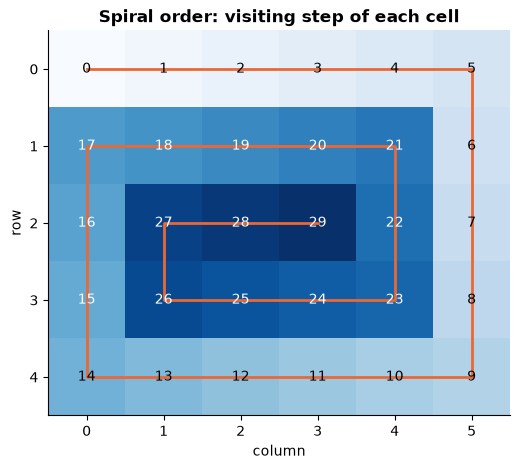

In [4]:
# Visualise the spiral path on a 5 x 6 matrix
R, C = 5, 6
grid = [[i * C + j for j in range(C)] for i in range(R)]
order = spiral_order(grid)
coords = [(v // C, v % C) for v in order]                  # (row, col) of each visited cell
fig, ax = plt.subplots(figsize=(6, 5))
step = np.zeros((R, C))
for k, (i, j) in enumerate(coords):
    step[i, j] = k
ax.imshow(step, cmap="Blues")
for k, (i, j) in enumerate(coords):
    ax.text(j, i, k, ha="center", va="center", color="black" if k < 15 else "white", fontsize=10)
ys, xs = zip(*coords)
ax.plot(xs, ys, "-", color=PALETTE[1], lw=2)
ax.set(title="Spiral order: visiting step of each cell", xticks=range(C), yticks=range(R), xlabel="column", ylabel="row")
ax.grid(False); plt.show()

**What just happened?** Our transpose and in-place rotation match NumPy's `.T` and `np.rot90(k=-1)` on 300 random matrices, and the boundary-based spiral matches a slower "peel the top row and rotate" reference. In the picture the numbers are the visiting order: the path runs around the outer ring, then spirals inwards.

**Complexity:** all three are **O(R·C)** time (each cell is touched a constant number of times). Transpose returns a new matrix (O(R·C) space); the rotation is in place (O(1) extra); spiral uses O(1) besides the output.

> ⚠️ **Common mistake:** `[[0] * C] * R` creates R references to the *same* row, so changing one row changes all. Use `[[0] * C for _ in range(R)]`.

---
## 3. Strings

> 💡 **In plain English:** Python strings can't be changed in place, so build them with join, and use simple counting for palindromes and anagrams.

A **string** is a sequence of characters. In Python, `str` is an **immutable** sequence of Unicode code points: once created it cannot change. Every "modification" creates a new string.

Why immutable? Strings can then be safely shared, used as dict keys (their hash never changes) and cached.

**Building strings efficiently.** `s = s + piece` in a loop copies the whole string each time, so building a string of n pieces can cost 1 + 2 + … + n = **O(n²)** character copies in the worst case. `"".join(pieces)` computes the final length once and copies each piece once: **O(n)**. (CPython has an optimisation that sometimes extends a string in place for `s += t`, but it is an implementation detail that other Pythons, and even CPython in some situations, do not apply. `join` is the guaranteed-linear idiom.)

In [5]:
s = "hello"
try:
    s[0] = "H"                                  # strings are immutable
except TypeError as e:
    print("TypeError:", e)
t = "H" + s[1:]                                 # build a NEW string instead
print(s, "->", t, "| same object?", s is t)

def build_concat(n):
    out = ""
    for i in range(n):
        out = out + "x"                          # new string each time (may be optimised by CPython)
    return out

def build_join(n):
    parts = []
    for i in range(n):
        parts.append("x")                        # O(1) amortized
    return "".join(parts)                        # one pass, O(total length)

def build_concat_no_opt(n):
    """Keep an extra reference so CPython CANNOT extend in place: shows the true O(n^2) cost."""
    out, keep = "", None
    for i in range(n):
        keep = out                               # a second reference to the old string
        out = out + "x"
    return out

for n in [20_000, 80_000]:
    times = {f.__name__: min(timeit.repeat(lambda: f(n), number=1, repeat=5)) for f in (build_concat, build_join, build_concat_no_opt)}
    print(f"n = {n:>6,}: " + " | ".join(f"{k} {v * 1000:7.2f} ms" for k, v in times.items()))

# Timings are noisy; counting the characters each method COPIES is exact:
for n in [20_000, 80_000]:
    copies_no_opt = sum(range(1, n + 1))       # step i copies the i-1 old chars + 1 new char
    copies_join = n                            # join copies each piece exactly once
    print(f"n = {n:>6,}: characters copied: concat without the optimisation {copies_no_opt:>13,} | join {copies_join:>7,}")
assert build_concat(100) == build_join(100) == build_concat_no_opt(100) == "x" * 100

TypeError: 'str' object does not support item assignment
hello -> Hello | same object? False


n = 20,000: build_concat    6.35 ms | build_join    4.04 ms | build_concat_no_opt   27.18 ms


n = 80,000: build_concat   25.65 ms | build_join   18.53 ms | build_concat_no_opt  256.90 ms
n = 20,000: characters copied: concat without the optimisation   200,010,000 | join  20,000
n = 80,000: characters copied: concat without the optimisation 3,200,040,000 | join  80,000


**What just happened?** Item assignment raised `TypeError`, proving immutability. In the timings, `build_concat_no_opt` is the slowest. Plain `+` may look fine because CPython quietly extends the string in place when nothing else references it; as soon as another reference exists (`build_concat_no_opt`), each `+` must copy the whole string. The exact copy counts show why: n(n+1)/2 characters (about 3.2 billion for n = 80,000, **16×** more than for n = 20,000) versus n for `join` (only 4× more). At these sizes copying is a fast `memcpy`, so the measured times grow by less than 16× (and timings on a busy computer are noisy), but the quadratic term wins for long strings. Rely on `join`, not on the optimisation.

### Palindromes and anagrams
- A **palindrome** reads the same forwards and backwards ("racecar"; ignoring case and punctuation, "A man, a plan, a canal: Panama").
- Two strings are **anagrams** if one is a rearrangement of the other ("listen" / "silent").

In [6]:
from collections import Counter

def is_palindrome(s):
    """Two pointers from both ends, skipping non-alphanumeric characters. O(n) time, O(1) space."""
    i, j = 0, len(s) - 1
    while i < j:
        if not s[i].isalnum():   i += 1; continue
        if not s[j].isalnum():   j -= 1; continue
        if s[i].lower() != s[j].lower():
            return False
        i += 1; j -= 1
    return True

def is_palindrome_brute(s):
    cleaned = [c.lower() for c in s if c.isalnum()]     # O(n) extra space
    return cleaned == cleaned[::-1]

def is_anagram_sort(a, b):
    return sorted(a) == sorted(b)                        # O(n log n)

def is_anagram_count(a, b):
    """Count letters: O(n) time, O(k) space for an alphabet of size k."""
    if len(a) != len(b):
        return False
    counts = {}
    for ch in a: counts[ch] = counts.get(ch, 0) + 1
    for ch in b:
        if counts.get(ch, 0) == 0:
            return False
        counts[ch] -= 1
    return True

for s in ["racecar", "A man, a plan, a canal: Panama", "hello", "", "No 'x' in Nixon"]:
    print(f"{s!r:36} palindrome? {is_palindrome(s)}")
print("listen/silent anagram?", is_anagram_count("listen", "silent"), "| apple/paple?", is_anagram_count("apple", "paple"), "| rat/car?", is_anagram_count("rat", "car"))

alpha = "abA ,b"
print(random_tests(2000, lambda: ("".join(random.choices(alpha, k=random.randint(0, 9))),), is_palindrome, is_palindrome_brute))
def counter_equal(a, b):
    return Counter(a) == Counter(b)                       # library reference
print(random_tests(2000, lambda: ("".join(random.choices("abc", k=random.randint(0, 6))), "".join(random.choices("abc", k=random.randint(0, 6)))),
                   is_anagram_sort, is_anagram_count, counter_equal))

'racecar'                            palindrome? True
'A man, a plan, a canal: Panama'     palindrome? True
'hello'                              palindrome? False
''                                   palindrome? True
"No 'x' in Nixon"                    palindrome? True
listen/silent anagram? True | apple/paple? True | rat/car? False
2000 random tests passed: is_palindrome == is_palindrome_brute
2000 random tests passed: is_anagram_sort == is_anagram_count == counter_equal


**What just happened?** The two-pointer palindrome check agrees with the "clean and reverse" brute force on 2000 random strings (including spaces, commas and mixed case), and the counting anagram check agrees with sorting and with `collections.Counter`. The two-pointer idea in `is_palindrome` is our first pattern: let's study it properly.

---
## 4. Pattern 1 — Two pointers

> 💡 **In plain English:** two pointers walk through the data from both ends (or at two speeds) so you never test the same pair twice.

**Intuition.** Two people search a sorted bookshelf for two books whose prices add up to a budget: one starts at the cheap end, one at the expensive end, and they walk towards each other.

**Two pointers** means maintaining two indices that move through the data (towards each other, or in the same direction at different speeds) so that each step discards part of the search space. It typically turns an **O(n²)** all-pairs search into **O(n)**.

**When to use it:** the array is **sorted** (or can be sorted), you look for a **pair/triple** with some sum/property, or you must **compact/partition an array in place**.

### Problem 1: pair with a given sum in a sorted array
Sorted `a = [1, 3, 4, 6, 8, 11]`, target 10:

| step | i (a[i]) | j (a[j]) | sum | action |
|---|---|---|---|---|
| 1 | 0 (1) | 5 (11) | 12 | too big → j−− (11 can't pair with anything ≥ 1) |
| 2 | 0 (1) | 4 (8) | 9 | too small → i++ (1 can't pair with anything ≤ 8) |
| 3 | 1 (3) | 4 (8) | 11 | too big → j−− |
| 4 | 1 (3) | 3 (6) | 9 | too small → i++ |
| 5 | 2 (4) | 3 (6) | 10 | **found** |

Why is it correct? When the sum is too big, a[j] plus the *smallest* remaining element is already too big, so a[j] can be discarded forever (and symmetrically for i).

In [7]:
def pair_sum_brute(a, target):
    """O(n^2): try every pair. Returns a pair of indices (i, j) with i < j, or None."""
    for i in range(len(a)):
        for j in range(i + 1, len(a)):
            if a[i] + a[j] == target:
                return (i, j)
    return None

def pair_sum_two_pointers(a, target, trace=None):
    """O(n) on a SORTED array."""
    i, j = 0, len(a) - 1
    while i < j:
        s = a[i] + a[j]
        if trace is not None: trace.append({"i": i, "j": j, "a[i]": a[i], "a[j]": a[j], "sum": s})
        if s == target:
            return (i, j)
        if s < target:
            i += 1          # need a bigger sum: move the left pointer right
        else:
            j -= 1          # need a smaller sum: move the right pointer left
    return None

tr = []
print("result:", pair_sum_two_pointers([1, 3, 4, 6, 8, 11], 10, tr))
display(pd.DataFrame(tr))

def gen():
    a = sorted(random.randint(-20, 20) for _ in range(random.randint(0, 12)))
    return a, random.randint(-40, 40)
# The two functions may return different (valid) pairs, so compare "found or not" and validity
for _ in range(3000):
    a, t = gen()
    b, p = pair_sum_brute(a, t), pair_sum_two_pointers(a, t)
    assert (b is None) == (p is None)
    if p: assert p[0] < p[1] and a[p[0]] + a[p[1]] == t
print("3000 random sorted arrays: two pointers finds a pair exactly when brute force does")

result: (2, 3)


,i,j,a[i],a[j],sum
0,0,5,1,11,12
1,0,4,1,8,9
2,1,4,3,8,11
3,1,3,3,6,9
4,2,3,4,6,10


3000 random sorted arrays: two pointers finds a pair exactly when brute force does


**What just happened?** The trace table reproduces our hand-worked steps and finds indices (2, 3), i.e. 4 + 6 = 10. On 3000 random sorted arrays the two-pointer version finds a valid pair exactly when brute force does. **Complexity:** brute force O(n²) time; two pointers **O(n)** time (each step moves a pointer, at most n steps), O(1) space.

### Problem 2: container with most water
Given heights h, choose two lines i < j to maximise the water area **(j − i) × min(h[i], h[j])**. Start with the widest container; the shorter line limits the area, and moving the *taller* line inwards can never help (width shrinks, height stays capped by the shorter line), so always move the shorter one.

### Problem 3: remove duplicates from a sorted array in place
A **slow** pointer marks where the next unique value goes; a **fast** pointer scans. (Same-direction two pointers.)

### Problem 4: 3-sum
Find all unique triples with sum 0. Sort, fix the first element, then run two pointers on the rest: **O(n²)** instead of O(n³).

In [8]:
# ---- container with most water
def max_area_brute(h):
    return max(((j - i) * min(h[i], h[j]) for i in range(len(h)) for j in range(i + 1, len(h))), default=0)

def max_area(h):
    i, j, best = 0, len(h) - 1, 0
    while i < j:
        best = max(best, (j - i) * min(h[i], h[j]))
        if h[i] < h[j]:
            i += 1              # the shorter line limits the area: discard it
        else:
            j -= 1
    return best

# ---- remove duplicates in place (sorted input); returns the new length k, a[:k] holds unique values
def remove_duplicates(a):
    if not a:
        return 0
    slow = 0                                   # a[:slow+1] is the unique prefix so far
    for fast in range(1, len(a)):
        if a[fast] != a[slow]:                 # a new value: extend the unique prefix
            slow += 1
            a[slow] = a[fast]
    return slow + 1

# ---- 3-sum
def three_sum_brute(a):
    n, res = len(a), set()
    for i in range(n):
        for j in range(i + 1, n):
            for k in range(j + 1, n):
                if a[i] + a[j] + a[k] == 0:
                    res.add(tuple(sorted((a[i], a[j], a[k]))))
    return sorted(res)

def three_sum(a):
    a = sorted(a)
    res = []
    for i in range(len(a) - 2):
        if i > 0 and a[i] == a[i - 1]:          # skip duplicate first elements
            continue
        lo, hi = i + 1, len(a) - 1
        while lo < hi:
            s = a[i] + a[lo] + a[hi]
            if s < 0:   lo += 1
            elif s > 0: hi -= 1
            else:
                res.append((a[i], a[lo], a[hi]))
                lo += 1; hi -= 1
                while lo < hi and a[lo] == a[lo - 1]:   # skip duplicate second elements
                    lo += 1
    return res

print("max_area([1,8,6,2,5,4,8,3,7]) =", max_area([1, 8, 6, 2, 5, 4, 8, 3, 7]))
arr = [0, 0, 1, 1, 1, 2, 2, 3, 3, 4]; k = remove_duplicates(arr)
print("remove_duplicates →", k, arr[:k])
print("three_sum([-1,0,1,2,-1,-4]) =", three_sum([-1, 0, 1, 2, -1, -4]))

print(random_tests(2000, lambda: ([random.randint(0, 15) for _ in range(random.randint(0, 12))],), max_area_brute, max_area))
def remove_duplicates_result(a):
    b = a[:]; k = remove_duplicates(b); return b[:k]
def unique_sorted(a):
    return sorted(set(a))                                  # library reference
print(random_tests(2000, lambda: (sorted(random.randint(0, 6) for _ in range(random.randint(0, 12))),),
                   remove_duplicates_result, unique_sorted))
print(random_tests(1000, lambda: ([random.randint(-6, 6) for _ in range(random.randint(0, 11))],), three_sum_brute, three_sum))

max_area([1,8,6,2,5,4,8,3,7]) = 49
remove_duplicates → 5 [0, 1, 2, 3, 4]
three_sum([-1,0,1,2,-1,-4]) = [(-1, -1, 2), (-1, 0, 1)]


2000 random tests passed: max_area_brute == max_area
2000 random tests passed: remove_duplicates_result == unique_sorted


1000 random tests passed: three_sum_brute == three_sum


**What just happened?** The optimal versions agree with brute force on thousands of random inputs. The famous example `[1,8,6,2,5,4,8,3,7]` gives area 49 (lines at index 1 and 8: width 7 × height 7).

| Problem | Brute force | Two pointers | Space |
|---|---|---|---|
| pair sum (sorted) | O(n²) | O(n) | O(1) |
| container with most water | O(n²) | O(n) | O(1) |
| remove duplicates (sorted) | O(n) with a new list / set | O(n) **in place** | O(1) |
| 3-sum | O(n³) | O(n²) (sort O(n log n) + n two-pointer scans) | O(1) besides output and the sort |

> 🎓 **Exam / interview tip:** for the pair-sum problem on an *unsorted* array, use a hash set instead (O(n) time, O(n) space, notebook 04). Sorting first + two pointers costs O(n log n) but only O(1) extra space. Mention both and the trade-off.

---
## 5. Pattern 2 — Sliding window

> 💡 **In plain English:** a sliding window keeps a running answer for a block of neighbours and updates it as the block moves.

**Intuition.** Looking at a long photo strip through a window frame: instead of re-reading everything inside the frame each time you slide it one step, you only note the photo that entered and the one that left.

A **sliding window** is a contiguous range `[left, right]` that moves through the array, updating an aggregate (sum, counts, set of characters) incrementally in O(1) per step.
- **Fixed-size window** (size k): add the element entering on the right, remove the one leaving on the left.
- **Variable-size window**: extend `right` every step; shrink from `left` while the window violates (or satisfies) a condition.

**When to use it:** the problem asks about **contiguous** subarrays/substrings ("longest/shortest/max-sum subarray with property X") and the property can be updated incrementally. (For *non-contiguous* subsets you need other tools, e.g. DP.)

### Problem 1 (fixed): maximum sum of a subarray of size k
`a = [2, 1, 5, 1, 3, 2]`, k = 3:

| window | computed as | sum |
|---|---|---|
| [2, 1, 5] | 2 + 1 + 5 | 8 |
| [1, 5, 1] | 8 − 2 + 1 | 7 |
| [5, 1, 3] | 7 − 1 + 3 | **9** |
| [1, 3, 2] | 9 − 5 + 2 | 6 |

max_sum_k([2,1,5,1,3,2], 3) = 9


3000 random tests passed: max_sum_k_brute == max_sum_k


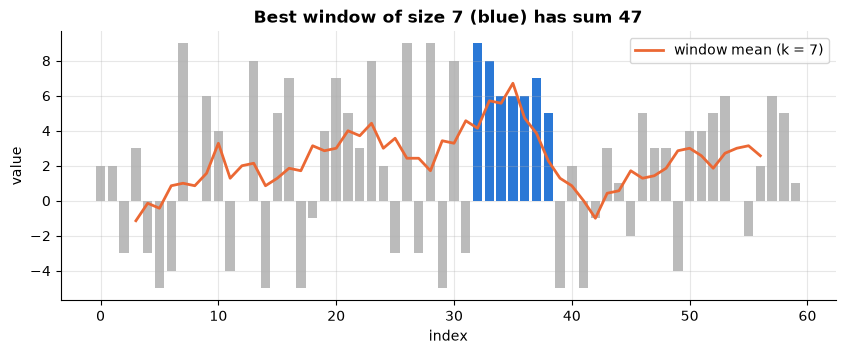

In [9]:
def max_sum_k_brute(a, k):
    """O(n·k): sum every window from scratch."""
    return max(sum(a[i:i + k]) for i in range(len(a) - k + 1))

def max_sum_k(a, k):
    """O(n): slide the window, add the new element, subtract the old one."""
    window = sum(a[:k])
    best = window
    for right in range(k, len(a)):
        window += a[right] - a[right - k]      # one element enters, one leaves
        best = max(best, window)
    return best

print("max_sum_k([2,1,5,1,3,2], 3) =", max_sum_k([2, 1, 5, 1, 3, 2], 3))
def gen():
    a = [random.randint(-10, 10) for _ in range(random.randint(1, 15))]
    return a, random.randint(1, len(a))
print(random_tests(3000, gen, max_sum_k_brute, max_sum_k))

# Visualise every window sum for a longer random series
a = np.random.randint(-5, 10, size=60).tolist(); k = 7
sums = [sum(a[i:i + k]) for i in range(len(a) - k + 1)]
best_i = int(np.argmax(sums))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(a)), a, color=["#bbbbbb" if not best_i <= i < best_i + k else PALETTE[0] for i in range(len(a))])
ax.plot(np.arange(len(sums)) + (k - 1) / 2, np.array(sums) / k, color=PALETTE[1], label=f"window mean (k = {k})")
ax.set(title=f"Best window of size {k} (blue) has sum {max(sums)}", xlabel="index", ylabel="value")
ax.legend(); plt.show()
assert max(sums) == max_sum_k(a, k)

**What just happened?** The sliding version returns 9 for the hand example and matches brute force on 3000 random arrays (including negative numbers). The plot highlights the best window of size 7 in a random series; the orange line is the moving average, which is exactly a sliding-window sum divided by k (this is how rolling features in time series are computed).

**Complexity:** brute force O(n·k); sliding window **O(n)** time, O(1) space.

### Problem 2 (variable): longest substring without repeating characters
Expand `right`; if the new character is already in the window, move `left` just past its previous occurrence. Track the last index of each character in a dict.

| right | char | last seen | left | window | best |
|---|---|---|---|---|---|
| 0 | a | – | 0 | a | 1 |
| 1 | b | – | 0 | ab | 2 |
| 2 | c | – | 0 | abc | 3 |
| 3 | a | 0 | 1 | bca | 3 |
| 4 | b | 1 | 2 | cab | 3 |
| 5 | c | 2 | 3 | abc | 3 |
| 6 | b | 4 | 5 | cb | 3 |
| 7 | b | 6 | 7 | b | 3 |

### Problem 3 (variable): minimum window substring
Smallest window of `s` containing every character of `t` (with multiplicity). Expand `right` until the window is *valid*, then shrink `left` as long as it stays valid, recording the smallest.

In [10]:
def longest_unique_brute(s):
    """O(n^3)-ish: check every substring."""
    best = 0
    for i in range(len(s)):
        for j in range(i, len(s)):
            if len(set(s[i:j + 1])) == j - i + 1:
                best = max(best, j - i + 1)
    return best

def longest_unique(s):
    """O(n): variable window, dict of last positions."""
    last = {}
    left = best = 0
    for right, ch in enumerate(s):
        if ch in last and last[ch] >= left:   # ch repeats inside the window
            left = last[ch] + 1                # jump left past the previous ch
        last[ch] = right
        best = max(best, right - left + 1)
    return best

def min_window_brute(s, t):
    need = Counter(t)
    best = ""
    for i in range(len(s)):
        for j in range(i, len(s)):
            sub = s[i:j + 1]
            if not need - Counter(sub) and (best == "" or len(sub) < len(best)):
                best = sub
    return best

def min_window(s, t):
    """O(|s| + |t|): expand right until valid, shrink left while valid."""
    if not t:
        return ""
    need = Counter(t)                 # how many of each char we still need
    missing = len(t)                  # total chars still missing
    left = 0
    best = (float("inf"), 0, 0)
    for right, ch in enumerate(s):
        if need[ch] > 0:
            missing -= 1
        need[ch] -= 1                 # can go negative: surplus copies inside the window
        while missing == 0:           # window is valid: try to shrink it
            if right - left + 1 < best[0]:
                best = (right - left + 1, left, right + 1)
            need[s[left]] += 1
            if need[s[left]] > 0:     # we just removed a needed char: window becomes invalid
                missing += 1
            left += 1
    return "" if best[0] == float("inf") else s[best[1]:best[2]]

print("longest_unique('abcabcbb') =", longest_unique("abcabcbb"))
print("min_window('ADOBECODEBANC', 'ABC') =", min_window("ADOBECODEBANC", "ABC"))
print(random_tests(3000, lambda: ("".join(random.choices("abcd", k=random.randint(0, 12))),), longest_unique_brute, longest_unique))
# several minimum windows can have the same length, so compare lengths and validity
for _ in range(1500):
    s = "".join(random.choices("abc", k=random.randint(0, 10))); t = "".join(random.choices("abc", k=random.randint(1, 3)))
    w1, w2 = min_window_brute(s, t), min_window(s, t)
    assert len(w1) == len(w2) and (w2 == "" or not Counter(t) - Counter(w2)) and w2 in s
print("1500 random tests passed: min_window has the brute-force length and is valid")

longest_unique('abcabcbb') = 3
min_window('ADOBECODEBANC', 'ABC') = BANC
3000 random tests passed: longest_unique_brute == longest_unique


1500 random tests passed: min_window has the brute-force length and is valid


**What just happened?** `'abcabcbb'` gives 3 ("abc") and the minimum window of `'ADOBECODEBANC'` containing A, B, C is `'BANC'`. Both match brute force on thousands of random strings.

**Complexity:** in a variable window, `left` and `right` each move at most n times, so the total work is **O(n)** even though there is a `while` inside the `for` (an amortized argument, as in notebook 01). Space O(alphabet size).

> ⚠️ **Common mistake:** in `longest_unique`, forgetting the check `last[ch] >= left` makes `left` jump *backwards* when a character was seen before the current window (try "abba").

---
## 6. Pattern 3 — Prefix sums and difference arrays

> 💡 **In plain English:** running totals let you get the sum of any stretch with one subtraction.

**Intuition.** A car's odometer: to know how far you drove between Tuesday and Friday, subtract Tuesday's reading from Friday's. You don't re-add each day's trip.

The **prefix sum** array P has P[0] = 0 and **P[i] = a[0] + … + a[i−1]**. Then the sum of `a[l..r]` (inclusive) is **P[r+1] − P[l]**: O(n) preprocessing, then **O(1) per query**.

```
index:     0   1   2   3   4
a:         3   1   4   1   5
P:     0   3   4   8   9  14
sum(a[1..3]) = P[4] − P[1] = 9 − 3 = 6   (= 1 + 4 + 1 ✓)
```

A **difference array** is the inverse idea: D[i] = a[i] − a[i−1]. Adding v to the whole range `a[l..r]` becomes two O(1) updates, **D[l] += v and D[r+1] −= v**; a prefix sum of D rebuilds a. Great for many range updates followed by one read.

**When to use it:** many **range-sum queries** on a static array, many **range updates**, or "count subarrays whose sum is k" (prefix sums + hashing).

In [11]:
from itertools import accumulate

def prefix_sums(a):
    P = [0] * (len(a) + 1)
    for i, x in enumerate(a):
        P[i + 1] = P[i] + x          # running total
    return P

def range_sum(P, l, r):
    """Sum of a[l..r] inclusive in O(1)."""
    return P[r + 1] - P[l]

def apply_range_updates(n, updates):
    """updates = [(l, r, v), ...]: add v to a[l..r]. O(n + number_of_updates) with a difference array."""
    D = [0] * (n + 1)
    for l, r, v in updates:
        D[l] += v
        D[r + 1] -= v
    return list(accumulate(D[:n]))   # prefix sums of D rebuild the array

a = [3, 1, 4, 1, 5]
P = prefix_sums(a)
print("P =", P, "| sum(a[1..3]) =", range_sum(P, 1, 3))
assert P == [0] + list(accumulate(a))

for _ in range(500):                                    # random queries vs brute force
    a = [random.randint(-50, 50) for _ in range(random.randint(1, 30))]
    P = prefix_sums(a)
    l = random.randrange(len(a)); r = random.randrange(l, len(a))
    assert range_sum(P, l, r) == sum(a[l:r + 1])
    n = len(a); ups = [(lambda l: (l, random.randrange(l, n), random.randint(-5, 5)))(random.randrange(n)) for _ in range(5)]
    brute = [0] * n
    for l2, r2, v in ups:
        for i in range(l2, r2 + 1): brute[i] += v
    assert apply_range_updates(n, ups) == brute
print("500 random tests passed: prefix-sum queries and difference-array updates match brute force")

# Speed: 5,000 range queries on 10,000 numbers
a = [random.randint(0, 100) for _ in range(10_000)]
queries = [sorted(random.sample(range(len(a)), 2)) for _ in range(5_000)]
t0 = time.perf_counter(); brute = [sum(a[l:r + 1]) for l, r in queries]; tb = time.perf_counter() - t0
t0 = time.perf_counter(); P = prefix_sums(a); fast = [range_sum(P, l, r) for l, r in queries]; tf = time.perf_counter() - t0
assert brute == fast
print(f"5,000 queries: slicing+sum {tb * 1000:.0f} ms | prefix sums {tf * 1000:.1f} ms")

P = [0, 3, 4, 8, 9, 14] | sum(a[1..3]) = 6
500 random tests passed: prefix-sum queries and difference-array updates match brute force


5,000 queries: slicing+sum 340 ms | prefix sums 7.6 ms


**What just happened?** The prefix array for `[3, 1, 4, 1, 5]` is `[0, 3, 4, 8, 9, 14]` and the range query returns 6. Random tests confirm both prefix-sum queries and difference-array range updates. With 5,000 queries on 10,000 numbers, recomputing each sum (O(n) per query) is far slower than one O(n) preprocessing pass plus O(1) per query.

### Subarray sum equals k (works with negative numbers)
Count subarrays with sum exactly k. A subarray `a[i..j]` has sum P[j+1] − P[i] = k, i.e. **P[i] = P[j+1] − k**. Scan once, keeping a hash map *count of each prefix sum seen so far*; at each position add `count[current − k]`.

Sliding window does **not** work here because with negative numbers, extending a window can *decrease* the sum, so there is no monotone rule for moving `left`.

In [12]:
def subarray_sum_k_brute(a, k):
    """O(n^2): try every start, extend the end."""
    count = 0
    for i in range(len(a)):
        s = 0
        for j in range(i, len(a)):
            s += a[j]
            count += (s == k)
    return count

def subarray_sum_k(a, k):
    """O(n): prefix sums + hash map of how often each prefix sum occurred."""
    seen = {0: 1}               # the empty prefix (sum 0) has occurred once
    prefix = count = 0
    for x in a:
        prefix += x
        count += seen.get(prefix - k, 0)       # earlier prefixes P[i] with P[i] = prefix - k
        seen[prefix] = seen.get(prefix, 0) + 1
    return count

print("subarray_sum_k([1, 1, 1], 2) =", subarray_sum_k([1, 1, 1], 2))
print("subarray_sum_k([3, 4, 7, -2, 2, 1, 4, 2], 7) =", subarray_sum_k([3, 4, 7, -2, 2, 1, 4, 2], 7))
print(random_tests(3000, lambda: ([random.randint(-4, 4) for _ in range(random.randint(0, 14))], random.randint(-5, 5)),
                   subarray_sum_k_brute, subarray_sum_k))

subarray_sum_k([1, 1, 1], 2) = 2
subarray_sum_k([3, 4, 7, -2, 2, 1, 4, 2], 7) = 6
3000 random tests passed: subarray_sum_k_brute == subarray_sum_k


**What just happened?** `[1, 1, 1]` with k = 2 has 2 such subarrays, and the classic example `[3, 4, 7, −2, 2, 1, 4, 2]` with k = 7 has 6 (e.g. [3, 4], [7], [7, −2, 2], [1, 4, 2] …). The hash-map version matches brute force on 3000 random arrays containing negatives and zeros. **Complexity:** O(n) average time, O(n) space (vs. O(n²) time, O(1) space).

---
## 7. Pattern 4 — Kadane's algorithm (maximum subarray sum)

> 💡 **In plain English:** Kadane's algorithm keeps the best sum ending here and starts fresh whenever the running sum turns negative.

**Problem.** Find the largest sum of a non-empty contiguous subarray. `[−2, 1, −3, 4, −1, 2, 1, −5, 4]` → 6 (subarray `[4, −1, 2, 1]`).

**Insight (dynamic programming in one variable).** Let `best_ending_here` be the best sum of a subarray that *ends* at the current index. Either we extend the previous best subarray, or we start fresh at the current element:

**best_ending_here = max(x, best_ending_here + x)**

If the running sum ever becomes negative, it only drags future subarrays down, so we drop it.

| i | x | best_ending_here | best_so_far |
|---|---|---|---|
| 0 | −2 | −2 | −2 |
| 1 | 1 | max(1, −1) = 1 | 1 |
| 2 | −3 | max(−3, −2) = −2 | 1 |
| 3 | 4 | max(4, 2) = 4 | 4 |
| 4 | −1 | 3 | 4 |
| 5 | 2 | 5 | 5 |
| 6 | 1 | **6** | **6** |
| 7 | −5 | 1 | 6 |
| 8 | 4 | 5 | 6 |

**When to use it:** maximum (or minimum) sum of a contiguous segment; variants include max circular subarray and max product subarray.

In [13]:
def max_subarray_brute(a):
    """O(n^2) using running sums."""
    best = a[0]
    for i in range(len(a)):
        s = 0
        for j in range(i, len(a)):
            s += a[j]
            best = max(best, s)
    return best

def kadane(a, trace=None):
    """O(n) time, O(1) space. Returns (best_sum, start, end) with a[start:end+1] optimal."""
    best_here, best = a[0], a[0]
    start = best_start = best_end = 0
    for i in range(1, len(a)):
        x = a[i]
        if best_here + x < x:          # starting fresh at i beats extending
            best_here, start = x, i
        else:
            best_here += x
        if best_here > best:
            best, best_start, best_end = best_here, start, i
        if trace is not None: trace.append({"i": i, "x": x, "best_ending_here": best_here, "best_so_far": best})
    return best, best_start, best_end

a = [-2, 1, -3, 4, -1, 2, 1, -5, 4]
best, s, e = kadane(a)
print(f"max subarray sum = {best}, subarray a[{s}:{e + 1}] = {a[s:e + 1]}")
print("all negative [-3, -1, -2] →", kadane([-3, -1, -2])[0])

def kadane_checked(a):
    best, s, e = kadane(a)
    assert sum(a[s:e + 1]) == best          # the returned indices really achieve the sum
    return best
print(random_tests(3000, lambda: ([random.randint(-10, 10) for _ in range(random.randint(1, 15))],), max_subarray_brute, kadane_checked))

max subarray sum = 6, subarray a[3:7] = [4, -1, 2, 1]
all negative [-3, -1, -2] → -1


3000 random tests passed: max_subarray_brute == kadane_checked

**What just happened?** Kadane finds sum 6 for `a[3:7] = [4, −1, 2, 1]`, handles the all-negative case correctly (answer −1, the largest single element, because the subarray must be non-empty), and agrees with brute force on 3000 random arrays while also returning indices that achieve the sum. **Complexity:** O(n) time, O(1) space vs. O(n²) brute force (O(n³) if each sum is recomputed).

> ⚠️ **Common mistake:** initialising `best = 0` gives the wrong answer (0) for all-negative arrays unless the empty subarray is allowed. Initialise with `a[0]`.

---
## 8. Pattern 5 — Stock buy/sell problems

> 💡 **In plain English:** for one trade, buy at the lowest price seen so far; for many trades, collect every daily rise.

Given daily prices, maximise profit.

**I. One transaction (buy once, sell later).** Track the **minimum price so far**; at each day the best sale is `price − min_so_far`. O(n). This is Kadane in disguise (max subarray of daily price differences).

**II. Unlimited transactions (but hold at most one share).** Every upward step can be captured: profit = **sum of all positive day-to-day differences**. Greedy, O(n). Why? Any profitable trade from day i to day j equals the sum of the daily differences between them; taking only the positive ones is at least as good.

`prices = [7, 1, 5, 3, 6, 4]`: one transaction → buy at 1, sell at 6 → **5**. Unlimited → (5 − 1) + (6 − 3) = **7**.

(At most k transactions, or with a cooldown/fee, needs dynamic programming; see [09 · Dynamic programming](09_dynamic_programming.ipynb).)

one transaction: 5 | unlimited: 7
2000 random tests passed: stock_one_brute == stock_one


1000 random tests passed: stock_unlimited_brute == stock_unlimited


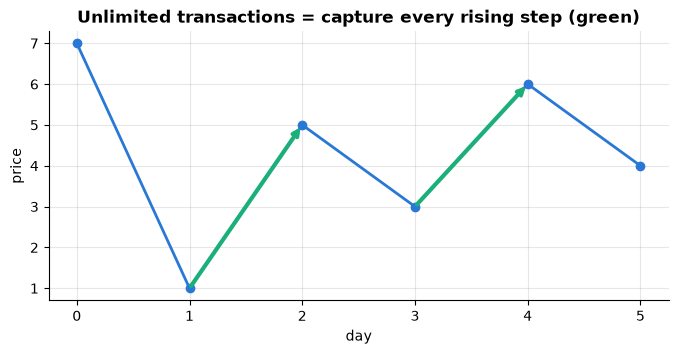

In [14]:
def stock_one_brute(p):
    """O(n^2): every (buy day, later sell day) pair; profit 0 if we never trade."""
    return max([0] + [p[j] - p[i] for i in range(len(p)) for j in range(i + 1, len(p))])

def stock_one(p):
    """Best single buy-then-sell profit (0 if prices only fall). O(n)."""
    min_price, best = float("inf"), 0
    for price in p:
        min_price = min(min_price, price)        # cheapest day to have bought so far
        best = max(best, price - min_price)      # sell today?
    return best

def stock_unlimited_brute(p, day=0, holding=False, memo=None):
    """Exhaustive search over hold/buy/sell decisions (fine for small inputs)."""
    if day == len(p):
        return 0
    best = stock_unlimited_brute(p, day + 1, holding)                       # do nothing today
    if holding:
        best = max(best, p[day] + stock_unlimited_brute(p, day + 1, False))  # sell today
    else:
        best = max(best, -p[day] + stock_unlimited_brute(p, day + 1, True))  # buy today
    return best

def stock_unlimited(p):
    """Sum of all positive daily gains. O(n)."""
    return sum(max(0, p[i] - p[i - 1]) for i in range(1, len(p)))

prices = [7, 1, 5, 3, 6, 4]
print("one transaction:", stock_one(prices), "| unlimited:", stock_unlimited(prices))
print(random_tests(2000, lambda: ([random.randint(1, 20) for _ in range(random.randint(0, 12))],), stock_one_brute, stock_one))
print(random_tests(1000, lambda: ([random.randint(1, 20) for _ in range(random.randint(0, 11))],), stock_unlimited_brute, stock_unlimited))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(prices, "o-", color=PALETTE[0])
for i in range(1, len(prices)):
    if prices[i] > prices[i - 1]:
        ax.annotate("", xy=(i, prices[i]), xytext=(i - 1, prices[i - 1]), arrowprops=dict(color=PALETTE[2], lw=3, arrowstyle="->"))
ax.set(title="Unlimited transactions = capture every rising step (green)", xlabel="day", ylabel="price"); plt.show()

**What just happened?** For `[7, 1, 5, 3, 6, 4]` we get 5 with one transaction and 7 with unlimited transactions, as computed by hand. The greedy formulas match an exhaustive search over every buy/sell decision sequence. The plot shows the two rising steps (1→5 and 3→6) that the greedy strategy captures.

---
## 9. Pattern 6 — Dutch national flag (3-way partition)

> 💡 **In plain English:** sort three kinds of items (like red, white, blue balls) in a single pass by growing three zones.

**Problem (Dijkstra).** Sort an array containing only 0s, 1s and 2s (red, white, blue) **in one pass, in place**.

Keep three regions with pointers `low`, `mid`, `high`:
```
[ 0 0 0 | 1 1 1 | ? ? ? ? | 2 2 2 ]
          ^low    ^mid    ^high
a[0..low-1] = 0,  a[low..mid-1] = 1,  a[mid..high] = unknown,  a[high+1..] = 2
```
Look at `a[mid]`: if 0, swap with `a[low]`, advance both; if 1, advance `mid`; if 2, swap with `a[high]` and shrink `high` (don't advance `mid`: the swapped-in element is still unknown).

**When to use it:** partition into three groups by a key (less than / equal to / greater than a pivot). It is the heart of **3-way quicksort**, which handles many duplicate keys well (notebook 03).

In [15]:
def dutch_flag(a, trace=None):
    low, mid, high = 0, 0, len(a) - 1
    while mid <= high:
        if trace is not None: trace.append({"array": "".join(map(str, a)), "low": low, "mid": mid, "high": high, "a[mid]": a[mid]})
        if a[mid] == 0:
            a[low], a[mid] = a[mid], a[low]
            low += 1; mid += 1
        elif a[mid] == 1:
            mid += 1
        else:                                    # a[mid] == 2
            a[mid], a[high] = a[high], a[mid]
            high -= 1                            # mid stays: new a[mid] not yet examined
    return a

def counting_brute(a):
    """Two-pass alternative: count 0s, 1s, 2s and rewrite (also O(n), but not one pass)."""
    c = [a.count(v) for v in (0, 1, 2)]
    return [0] * c[0] + [1] * c[1] + [2] * c[2]

tr = []
print(dutch_flag([2, 0, 2, 1, 1, 0], tr))
display(pd.DataFrame(tr))
def dutch_flag_copy(a):
    return dutch_flag(a[:])                                # don't modify the test input
print(random_tests(3000, lambda: ([random.randint(0, 2) for _ in range(random.randint(0, 15))],),
                   dutch_flag_copy, counting_brute, sorted))

[0, 0, 1, 1, 2, 2]


,array,low,mid,high,a[mid]
0,202110,0,0,5,2
1,002112,0,0,4,0
2,002112,1,1,4,0
3,002112,2,2,4,2
4,001122,2,2,3,1
5,001122,2,3,3,1


3000 random tests passed: dutch_flag_copy == counting_brute == sorted


**What just happened?** The trace shows each step: `low`, `mid`, `high` close in until the unknown region is empty, producing `[0, 0, 1, 1, 2, 2]`. It agrees with counting sort and `sorted` on 3000 random arrays. **Complexity:** O(n) time (each step either advances `mid` or shrinks `high`), O(1) space, one pass.

---
## 10. Bit manipulation basics

> 💡 **In plain English:** numbers are stored as 0s and 1s, and a few bit operations answer some questions in a single step.

Computers store integers in **binary** (base 2). 13 = 8 + 4 + 1 = `1101₂`. Bit i (counting from 0 at the right) has value 2ⁱ.

| Operator | Name | Rule (per bit) | Example (12 = `1100`, 10 = `1010`) |
|---|---|---|---|
| `a & b` | AND | 1 if both 1 | `1000` = 8 |
| `a \| b` | OR | 1 if either 1 | `1110` = 14 |
| `a ^ b` | XOR | 1 if different | `0110` = 6 |
| `~a` | NOT | flip every bit | −13 (see below) |
| `a << k` | left shift | multiply by 2ᵏ | 12 << 2 = 48 |
| `a >> k` | right shift | floor-divide by 2ᵏ | 12 >> 2 = 3 |

**Negative numbers: two's complement.** In a w-bit machine integer, −x is stored as 2ʷ − x, so the top bit acts as the sign and `~x = −x − 1`. Python integers have *unlimited* width and behave as if they had infinitely many sign bits, so `~12 == −13` and to see the 8-bit pattern you mask: `-13 & 0xFF = 0b11110011`.

Bit tricks (i is the bit position):

| Task | Code | Why |
|---|---|---|
| check bit i | `(x >> i) & 1` | move bit i to position 0 |
| set bit i | `x \| (1 << i)` | OR with a mask that has only bit i |
| clear bit i | `x & ~(1 << i)` | AND with all-ones except bit i |
| toggle bit i | `x ^ (1 << i)` | XOR flips |
| lowest set bit | `x & -x` | two's complement trick |
| clear lowest set bit | `x & (x - 1)` | x − 1 flips the lowest 1 and the 0s below it |
| power of two? | `x > 0 and x & (x - 1) == 0` | powers of two have exactly one 1 bit |

In [16]:
x, y = 12, 10
print(f"x = {x} = {x:04b}, y = {y} = {y:04b}")
print(f"x & y = {x & y:04b} ({x & y}) | x | y = {x | y:04b} ({x | y}) | x ^ y = {x ^ y:04b} ({x ^ y})")
print(f"~x = {~x} | 8-bit pattern of ~x: {(~x) & 0xFF:08b} | x << 2 = {x << 2} | x >> 2 = {x >> 2}")
assert ~x == -x - 1 and (x << 2) == x * 4 and (x >> 2) == x // 4

check  = lambda x, i: (x >> i) & 1
set_   = lambda x, i: x | (1 << i)
clear  = lambda x, i: x & ~(1 << i)
toggle = lambda x, i: x ^ (1 << i)
print(f"13 = {13:04b}: bit1 = {check(13, 1)}, set bit1 → {set_(13, 1):04b}, clear bit2 → {clear(13, 2):04b}, toggle bit0 → {toggle(13, 0):04b}")

def count_bits_loop(x):
    """Check every bit: O(number of bits)."""
    c = 0
    while x:
        c += x & 1
        x >>= 1
    return c

def count_bits_kernighan(x):
    """Brian Kernighan: each step clears the lowest set bit, so O(number of SET bits)."""
    c = 0
    while x:
        x &= x - 1
        c += 1
    return c

def is_power_of_two(x):
    return x > 0 and x & (x - 1) == 0

for _ in range(5000):
    v = random.getrandbits(random.randint(1, 64))
    assert count_bits_loop(v) == count_bits_kernighan(v) == bin(v).count("1") == v.bit_count()   # int.bit_count(): Python 3.10+
    assert is_power_of_two(v) == (v > 0 and v == 2 ** (v.bit_length() - 1))
print("5000 random 64-bit tests passed: bit counting and power-of-two checks")

x = 12 = 1100, y = 10 = 1010
x & y = 1000 (8) | x | y = 1110 (14) | x ^ y = 0110 (6)
~x = -13 | 8-bit pattern of ~x: 11110011 | x << 2 = 48 | x >> 2 = 3
13 = 1101: bit1 = 0, set bit1 → 1111, clear bit2 → 1001, toggle bit0 → 1100


5000 random 64-bit tests passed: bit counting and power-of-two checks


**What just happened?** The operators behave as in the table (`~12` is −13, whose 8-bit two's-complement pattern is `11110011`). Both bit-counting methods match Python's built-in `int.bit_count()` and `bin(v).count("1")` on 5000 random numbers up to 64 bits, and the power-of-two test matches a direct definition.

### The single-number XOR trick
Every number in a list appears **twice** except one. Find it in O(n) time and **O(1) space**. XOR facts: `a ^ a = 0`, `a ^ 0 = a`, and XOR is commutative and associative. XOR-ing everything cancels the pairs and leaves the single one:
`4 ^ 1 ^ 2 ^ 1 ^ 2 = 4 ^ (1 ^ 1) ^ (2 ^ 2) = 4 ^ 0 ^ 0 = 4`.

### Bitmasks as subsets
An n-bit number can represent a subset of n items (bit i = "item i is in the set"). Looping `mask` from 0 to 2ⁿ − 1 enumerates all subsets: the basis of brute-force search and of bitmask DP.

In [17]:
from functools import reduce
from operator import xor

def single_number(a):
    return reduce(xor, a, 0)            # pairs cancel out

def single_number_brute(a):
    c = Counter(a)
    return next(v for v, k in c.items() if k == 1)

print("single_number([4, 1, 2, 1, 2]) =", single_number([4, 1, 2, 1, 2]))
def gen():
    pairs = random.sample(range(-1000, 1000), random.randint(0, 10))
    single = random.choice([v for v in range(-1000, 1000) if v not in pairs])
    a = pairs * 2 + [single]; random.shuffle(a)
    return (a,)
print(random_tests(2000, gen, single_number, single_number_brute))

items = ["a", "b", "c"]
subsets = [[items[i] for i in range(len(items)) if (mask >> i) & 1] for mask in range(1 << len(items))]
print("all subsets via bitmasks:", subsets)

single_number([4, 1, 2, 1, 2]) =

 4


2000 random tests passed: single_number == single_number_brute
all subsets via bitmasks: [[], ['a'], ['b'], ['a', 'b'], ['c'], ['a', 'c'], ['b', 'c'], ['a', 'b', 'c']]


**What just happened?** XOR-ing `[4, 1, 2, 1, 2]` returns 4, and it agrees with a Counter-based brute force (which needs O(n) extra space) on 2000 random lists including negative numbers. The bitmask loop lists all 2³ = 8 subsets of `{a, b, c}`.

> 🎓 **Exam / interview tip:** state *why* bit tricks work (e.g. "x − 1 flips the lowest set bit and all zeros below it, so x & (x − 1) clears it"). Interviewers care about the reasoning more than the one-liner.

---
## 11. Which pattern when?

> 💡 **In plain English:** match the clues in a problem statement to the pattern that solves it.

| Pattern | Signal in the problem statement | Typical complexity |
|---|---|---|
| **Two pointers** (opposite ends) | sorted array; find a pair/triple with a target sum; palindrome; maximise something over pairs | O(n) (O(n²) for 3-sum) |
| **Two pointers** (slow/fast) | modify an array in place; remove/compact elements; cycle detection in linked lists | O(n), O(1) space |
| **Sliding window** (fixed) | "every subarray/substring of length k" | O(n) |
| **Sliding window** (variable) | "longest/shortest contiguous segment such that…" with non-negative values or counts | O(n) |
| **Prefix sums** | many range-sum queries; "subarray sum equals k" (with a hash map; works with negatives) | O(n) preprocess, O(1) query |
| **Difference array** | many range *updates*, then read once | O(n + updates) |
| **Kadane** | maximum-sum contiguous subarray | O(n), O(1) space |
| **Greedy on differences** | stock trading with unlimited transactions | O(n) |
| **Dutch national flag** | partition into 3 groups in place, one pass | O(n), O(1) space |
| **Bit manipulation** | "each element appears twice except…", subsets, powers of two, flags | O(n) or O(1) |

## 🔗 How this connects to modern AI
- **Vectorised arrays are the foundation of ML.** NumPy, PyTorch and JAX tensors are contiguous strided arrays; a "transpose" is often just a change of strides, which is why `.contiguous()` exists in PyTorch. See [NumPy](../../02_Data_Analysis/02_numpy.ipynb) and [linear algebra](../../14_Mathematics/01_linear_algebra.ipynb).
- **Sliding windows** create rolling features for forecasting (rolling mean/max over the last k days; see [time series basics](../../04_Forecasting/01_time_series_basics.ipynb)), and LLMs such as Mistral 7B use *sliding-window attention* so each token attends to only the previous W tokens.
- **Prefix sums** are `np.cumsum`: used for cumulative distributions when sampling the next token from an LLM's probability distribution (nucleus/top-p sampling uses sort + cumulative sum, see notebook 03), for integral images in classic computer vision (Viola–Jones face detection), and for O(1) range statistics in feature pipelines.
- **Kadane-style running maxima** appear in anomaly detection and in drawdown metrics for trading models.
- **Bits:** model quantisation packs weights into 8, 4 or even fewer bits using shifts and masks (see [LLM inference optimisation](../../08_LLM/13_inference_optimization.ipynb)); Bloom filters and feature hashing (notebook 04) are bit arrays.

---
## Recap
- Arrays give **O(1) random access** because elements are contiguous: address = base + i × size. Python lists hold pointers; NumPy arrays hold raw numbers and are much faster for numeric work.
- Matrices are stored row-major in NumPy/C; rotate 90° clockwise = transpose + reverse rows; spiral order uses four shrinking boundaries.
- Python strings are **immutable**: build them with `"".join(...)`.
- **Two pointers** and **sliding windows** turn O(n²) scans into O(n) by never revisiting discarded positions.
- **Prefix sums** answer range sums in O(1); with a hash map they count "subarray sum = k" in O(n) even with negatives. **Difference arrays** do range updates in O(1).
- **Kadane**: best_ending_here = max(x, best_ending_here + x).
- **Stock problems**: track the minimum so far (one trade) or sum the positive differences (unlimited trades).
- **Dutch national flag**: one-pass, in-place 3-way partition.
- **Bits**: `x & (x−1)` clears the lowest set bit, XOR cancels pairs, masks represent subsets.

## Practice problems

**1. (Easy, conceptual)** A 2-D int32 array of shape (100, 200) is stored row-major starting at address 1000. What is the address of element (3, 7)? And in column-major order?

<details><summary>Show solution</summary>

Each element is 4 bytes. Row-major offset = (3 · 200 + 7) · 4 = 607 · 4 = 2428 → address **3428**.
Column-major offset = (7 · 100 + 3) · 4 = 703 · 4 = 2812 → address **3812**.

</details>

**2. (Easy, coding)** Move all zeros of a list to the end **in place** while keeping the relative order of the other elements.

<details><summary>Show solution</summary>

Slow/fast two pointers: O(n) time, O(1) space.
```python
def move_zeroes(a):
    """Move all zeros to the end in place, keeping the order of non-zeros. O(n), O(1) space."""
    slow = 0                               # next position for a non-zero
    for fast in range(len(a)):
        if a[fast] != 0:
            a[slow], a[fast] = a[fast], a[slow]
            slow += 1
    return a
```

</details>

**3. (Medium, coding)** Maximum subarray sum in a **circular** array (the subarray may wrap around the end).

<details><summary>Show solution</summary>

Either the best subarray doesn't wrap (plain Kadane), or it wraps, in which case it is the total minus the *minimum* subarray in the middle. Careful with the all-negative case.
```python
def max_subarray_circular(a):
    """Maximum sum of a non-empty subarray of a CIRCULAR array. O(n)."""
    def kadane_max(arr):
        best = cur = arr[0]
        for x in arr[1:]:
            cur = max(x, cur + x); best = max(best, cur)
        return best
    def kadane_min(arr):
        best = cur = arr[0]
        for x in arr[1:]:
            cur = min(x, cur + x); best = min(best, cur)
        return best
    straight = kadane_max(a)
    if straight < 0:                       # all negative: wrapping can't help
        return straight
    return max(straight, sum(a) - kadane_min(a))   # wrap-around = total minus the min middle part
```
Tested against an O(n²) brute force on 3000 random arrays.

</details>

**4. (Medium, coding)** Given a 0/1 array and k, return the length of the longest run of 1s if you may flip at most k zeros to 1.

<details><summary>Show solution</summary>

Variable sliding window that keeps at most k zeros inside. O(n).
```python
def longest_ones_with_k_flips(a, k):
    """Longest run of 1s in a 0/1 array if you may flip at most k zeros. Variable sliding window, O(n)."""
    left = zeros = best = 0
    for right, x in enumerate(a):
        zeros += (x == 0)
        while zeros > k:                   # too many zeros: shrink from the left
            zeros -= (a[left] == 0)
            left += 1
        best = max(best, right - left + 1)
    return best
```

</details>

**5. (Medium, coding)** Extend prefix sums to 2-D: answer many "sum of the sub-rectangle (r1, c1)–(r2, c2)" queries in O(1) each.

<details><summary>Show solution</summary>

S[i][j] = sum of the top-left i × j block. A rectangle sum uses inclusion–exclusion of four corners. O(R·C) preprocessing, O(1) per query. (This is the *integral image* used in Viola–Jones face detection.)
```python
def matrix_region_sums(M, queries):
    """2-D prefix sums: S[i][j] = sum of M[0..i-1][0..j-1]. Each query (r1, c1, r2, c2) in O(1)."""
    R, C = len(M), len(M[0])
    S = [[0] * (C + 1) for _ in range(R + 1)]
    for i in range(R):
        for j in range(C):
            S[i + 1][j + 1] = M[i][j] + S[i][j + 1] + S[i + 1][j] - S[i][j]   # inclusion-exclusion
    return [S[r2 + 1][c2 + 1] - S[r1][c2 + 1] - S[r2 + 1][c1] + S[r1][c1] for r1, c1, r2, c2 in queries]
```

</details>

**6. (Medium, coding)** An array has n distinct numbers taken from 0, 1, …, n (one is missing). Find the missing one in O(n) time and O(1) extra space without using arithmetic sums.

<details><summary>Show solution</summary>

XOR all indices 0..n with all values: every present number cancels.
```python
def missing_number(a):
    """a contains n distinct numbers from 0..n with one missing. XOR trick: O(n) time, O(1) space."""
    x = len(a)                       # start with n (the index loop below covers 0..n-1)
    for i, v in enumerate(a):
        x ^= i ^ v                   # every present number cancels with its index
    return x
```

</details>

**7. (Hard, coding, interview classic)** *Trapping rain water*: given bar heights, compute how much water is trapped after rain. Example: `[0,1,0,2,1,0,1,3,2,1,2,1]` → 6.

<details><summary>Show solution</summary>

Water above bar i = min(max height to the left, max height to the right) − h[i]. Two pointers: whichever side has the smaller wall is the limiting one, so its water level is already known.
```python
def trap_rain_water(h):
    """Units of water trapped between bars. Two pointers, O(n) time, O(1) space."""
    i, j = 0, len(h) - 1
    left_max = right_max = water = 0
    while i < j:
        if h[i] < h[j]:                  # the left side is the limiting wall
            left_max = max(left_max, h[i])
            water += left_max - h[i]
            i += 1
        else:
            right_max = max(right_max, h[j])
            water += right_max - h[j]
            j -= 1
    return water
```
O(n) time, O(1) space. Tested against the O(n²) definition on 3000 random inputs.

</details>

**8. (Conceptual, exam style)** Why does the sliding-window method fail for "longest subarray with sum ≤ k" when the array contains negative numbers, and what would you use instead?

<details><summary>Show solution</summary>

Sliding windows rely on **monotonicity**: with non-negative numbers, extending the window can only increase the sum, and shrinking can only decrease it, so once the sum exceeds k it is safe to move `left`. With negatives, adding an element can *decrease* the sum, so a window that is currently too big might become valid later, and moving `left` might throw away the answer. Use prefix sums instead: for each j, find the earliest i with P[i] ≥ P[j+1] − k. Since only *larger* prefixes matter, keep a running maximum of prefixes (which is non-decreasing) and binary-search it: **O(n log n)**.

</details>

## Further reading
- Cormen et al., *Introduction to Algorithms* (CLRS, 4th ed.), ch. 4.1 (maximum-subarray problem), ch. 10.1 (arrays and their representation in memory).
- Bentley, *Programming Pearls* (2nd ed.), column 8 (the maximum subarray story, including Kadane's linear algorithm).
- Warren, *Hacker's Delight* (2nd ed.), ch. 2 (basic bit tricks).
- GeeksforGeeks: [Array data structure](https://www.geeksforgeeks.org/array-data-structure-guide/), [Sliding window technique](https://www.geeksforgeeks.org/window-sliding-technique/), [Bitwise algorithms](https://www.geeksforgeeks.org/bitwise-algorithms/).
- NumPy documentation, *The N-dimensional array* (strides and memory layout): https://numpy.org/doc/stable/reference/arrays.ndarray.html

## Next notebook
➡️ [03 · Searching and Sorting](03_searching_and_sorting.ipynb): binary search and its variants, ten sorting algorithms implemented and benchmarked, the n log n lower bound, Timsort and quickselect.